<a href="https://colab.research.google.com/github/yerim410/AI/blob/main/Week11_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11주차 실습 — 백본 전이와 합성 데이터: 도메인 랜덤화 · MobileNetV3 · 세그 보조 · 모델 선택 표
**AI Application · 스마트모빌리티학과 · 2026-11-11**

| 셀 | 내용 |
|---|---|
| 0-1 | 이 머신의 속도 측정 → 예상 실행 시간, FAST |
| 1 | 스타일·저조도·노이즈 시각화 + 출발점 (v2 의 L1 / L3 저조도·노이즈 / L2 외란) |
| 2 | 도메인 랜덤화(밝기 0.3~1.0 · 노이즈 0.1~0.3 · 색) 데이터 1,500 프레임 → 이어서 학습 → 전후 (데이터 효과) |
| 3 | 사전학습 백본 MobileNetV3-small — 동결 vs 미세조정 (표현 효과 ①) |
| 4 | 세그멘테이션 보조 헤드 — 상태에서 렌더한 공짜 마스크 (표현 효과 ②) |
| 5 | 모델 선택 표 — 파라미터 · CPU 지연 · ONNX 크기 · L1 · L3 · L2 + 파레토 그림 → my_policy_v3.onnx |

**준비물**: `tinytrack.py` (0.3.0), Drive 의 `week07/my_policy_v2.pt` 와 `my_dataset_v2.npz` (없으면 v1 → 즉석, `models/base_pilotnet.pt` 필요), torchvision (Colab 기본). CPU 로 전체 8~10분.

In [11]:
from google.colab import drive
import sys

drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/AIApp")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# ============ 0. 준비 (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json, copy
for pkg in ["onnx", "onnxruntime", "pandas"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
assert tt.__version__ >= "0.3.0", "tinytrack 0.3.0 이상 필요"
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week11"; SAVE_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)
H, W = tt.H, tt.W
MODELS = Path("models") if Path("models/base_pilotnet.pt").exists() else Path(".")

for cand in [ROOT / "week07" / "my_dataset_v2.npz", ROOT / "week05" / "my_dataset_v1.npz"]:
    if cand.exists():
        D = tt.load_npz(cand); print("데이터:", cand.name, len(D["steers"])); break
else:
    print("데이터가 없어 즉석 생성 (약 20초)")
    D = tt.rebalance(tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
                                for n in "ABC" for k, ni in enumerate([0.0, 0.4, 0.8])]))
D = {k: D[k] for k in ("images", "steers", "states", "run_id")}
for cand in [ROOT / "week07" / "my_policy_v2.pt", ROOT / "week06" / "my_policy_v1.pt"]:
    if cand.exists():
        v2 = tt.load_model(cand); print("정책:", cand.name); break
else:
    if not (MODELS / "base_pilotnet.pt").exists():
        from google.colab import files
        print("base_pilotnet.pt 업로드"); files.upload()
    tr0, va0 = tt.split_by_run(D, 0.2, seed=0); v2 = tt.load_model(MODELS / "base_pilotnet.pt")
    tt.train_bc(v2, tr0, va0, epochs=3, lr=3e-4, augment=tt.make_augment(seed=0), verbose=False); print("정책: 즉석 미세조정")
torch.save(v2.state_dict(), SAVE_DIR / "v2.pt")

PUBLIC = ["A", "B", "C"]
L1 = tt.level_eval_kwargs("L1"); L2 = tt.level_eval_kwargs("L2")                    # L2: 외란 1.2×/40 (복구 축)
L3 = tt.level_eval_kwargs("L3", style_seed=7)                                      # L3: 외란 1.0× + 저조도(밝기 0.35) + 노이즈 0.12 + 색 랜덤화 (외관 축)
def score(pol, kw): return round(tt.evaluate(pol, PUBLIC, seed=0, **kw)["score"], 1)
def score3(pol): return dict(L1=score(pol, L1), L3=score(pol, L3), L2=score(pol, L2))
def batches(ds, idx, bs=64):
    for s in range(0, len(idx), bs):
        j = idx[s:s + bs]; yield j, torch.from_numpy(np.concatenate([tt.preprocess(im) for im in ds["images"][j]]))
print("tinytrack", tt.__version__, "| 프레임", len(D["steers"]), "| 저장:", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
데이터: my_dataset_v2.npz 4151
정책: my_policy_v2.pt
tinytrack 0.3.1 | 프레임 4151 | 저장: /content/drive/MyDrive/AIApp/week11


### 0-1. 이 머신의 속도 측정 (5초) → 예상 실행 시간과 `FAST`

In [13]:
import time as _t
_t0 = _t.time(); [tt.render(0.1, 0.05, 0.1) for _ in range(300)]; _tr = _t.time() - _t0
_m = tt.make_model().eval(); _x = torch.zeros(64, 3, tt.H, tt.W)
with torch.no_grad():
    _m(_x); _t0 = _t.time(); [_m(_x) for _ in range(10)]; _tf = _t.time() - _t0
REF_RENDER, REF_FWD, REF_MIN = 0.195, 0.318, 9
ratio = 0.5 * (_tr / REF_RENDER) + 0.5 * (_tf / REF_FWD)
FAST = os.environ.get("NB_FAST") == "1" or ratio > 1.8
N_TRAIN = 1500 if FAST else 2500          # 백본·세그 학습에 쓰는 프레임 수
print(f"렌더 300장 {_tr:.2f}s · 순전파 10회 {_tf:.2f}s → 제작 PC 대비 {ratio:.1f}배 → 예상 전체 실행 약 {REF_MIN * ratio * (0.7 if FAST else 1.0):.0f}분 | FAST = {FAST}")

렌더 300장 0.24s · 순전파 10회 1.10s → 제작 PC 대비 2.3배 → 예상 전체 실행 약 15분 | FAST = True


## 1. 스타일·저조도·노이즈 시각화 + 출발점
같은 상태 (d=0.1, ψ=0.05, κ=0.1) 를 여러 외관으로 렌더합니다. 색·그림자·차선 끊김에는 PilotNet 이 이미 강건합니다(도로의 **형태**를 보기 때문). 무너지는 것은 **저조도(밝기 0.35)와 센서 노이즈(0.12)** — 형태 자체가 흐려지는 조건. 여러분 v2 의 **L1 / L3(저조도·노이즈) / L2(외란)** 가 오늘의 출발점입니다.

{'model': 'PilotNet v2', 'L1': 86.7, 'L3': 25.4, 'L2': 17.3} (40s)  ← L3(저조도·노이즈) 가 오늘의 출발점


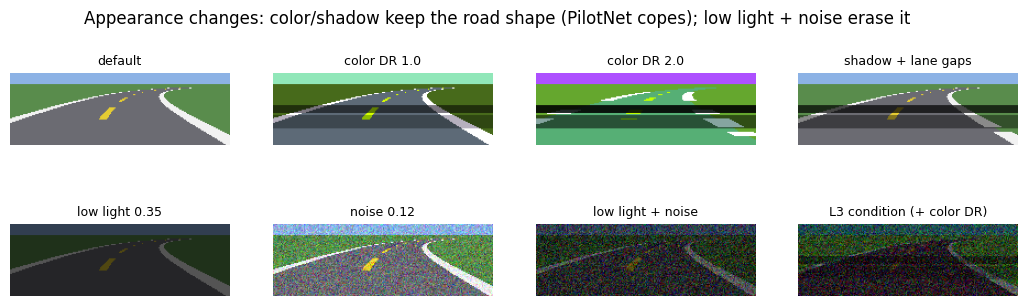

In [10]:
fig, ax = plt.subplots(2, 4, figsize=(13, 3.6))
views = [("default", None, 0.0), ("color DR 1.0", tt.random_style(1, 1.0), 0.0), ("color DR 2.0", tt.random_style(2, 2.0), 0.0), ("shadow + lane gaps", dict(shadow=0.8, lane_gap=0.4), 0.0),
         ("low light 0.35", dict(brightness=0.35), 0.0), ("noise 0.12", None, 0.12), ("low light + noise", dict(brightness=0.35), 0.12), ("L3 condition (+ color DR)", dict(tt.random_style(7, 1.0), brightness=0.35), 0.12)]
for a, (name, st, nz) in zip(ax.ravel(), views):
    a.imshow(tt.render(0.1, 0.05, 0.1, noise=nz, style=st, rng=np.random.RandomState(0))); a.set_title(name, fontsize=9); a.axis("off")
plt.suptitle("Appearance changes: color/shadow keep the road shape (PilotNet copes); low light + noise erase it")   # Colab 에는 한글 폰트가 없어 그림 글자는 영문; plt.tight_layout(); plt.savefig(SAVE_DIR / "styles.png", dpi=110); plt.show()
pol_v2 = tt.TorchPolicy(v2); t0 = time.time()
base_row = dict(model="PilotNet v2", **score3(pol_v2))
print(base_row, f"({time.time()-t0:.0f}s)  ← L3(저조도·노이즈) 가 오늘의 출발점")

## 2. 도메인 랜덤화 데이터 → 이어서 학습 (데이터 효과)
전문가로 **스타일 5개(색 랜덤화 + 밝기 0.3~1.0 + 저장 이미지 노이즈 0.1~0.3) × 트랙 A/B/C × 100 프레임 = 1,500 프레임**을 모아(노이즈 주입 0.4) 기존 데이터에 더하고, v2 에서 이어서 3에폭. 평가 조건(밝기 0.35, 노이즈 0.12, 미공개 시드 7)이 학습 분포의 한 표본이 되도록 범위를 잡았습니다.

In [14]:
t0 = time.time()
_r = np.random.RandomState(11)
DR = tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 100, seed=1000 + 10 * s + i, noise_inject=0.4,
                           style=dict(tt.random_style(100 + s, strength=1.0), brightness=float(_r.uniform(0.3, 1.0))), img_noise=float(_r.uniform(0.1, 0.3)))
                for s in range(5) for i, n in enumerate("ABC")])
print(f"랜덤화 데이터 {len(DR['steers'])} 프레임 ({time.time()-t0:.0f}s)")
rng = np.random.RandomState(0); keep = rng.choice(len(D["steers"]), min(2000, len(D["steers"])), replace=False)
D_mix = tt.merge({k: D[k][np.sort(keep)] for k in D}, DR)                     # 기존 2,000 + 랜덤화 1,500
tr, va = tt.split_by_run(D_mix, 0.2, seed=0)
pilot_dr = copy.deepcopy(v2); t0 = time.time()
tt.train_bc(pilot_dr, tr, va, epochs=3, lr=3e-4, augment=tt.make_augment(seed=0), save_path=SAVE_DIR / "pilot_dr.pt", verbose=False)
pol_dr = tt.TorchPolicy(pilot_dr)
dr_row = dict(model="PilotNet + 랜덤화", **score3(pol_dr))
print(base_row, "\n", dr_row, f"({time.time()-t0:.0f}s)")
print("읽는 법: L3(저조도·노이즈) 가 크게 오르고 L1 은 유지되면 '데이터 효과' — 단 대조군과 비교할 것.")
print("  제작 PC 대조군(시드 1개): 랜덤화 없이 기존 데이터로 3에폭만 더 → L3 61·L2 20 / 랜덤화 수집의 noise_inject 를 0 으로 → L3 18·L2 41")
print("  → L3 상승의 일부는 '더 학습한 것', 나머지는 '어두운 화면의 복구 장면'. L2(외란 1.2×) 도 랜덤화 데이터로 오른다 — 왜일까? (리포트 질문)")

랜덤화 데이터 1500 프레임 (5s)
{'model': 'PilotNet v2', 'L1': 86.7, 'L3': 25.4, 'L2': 17.3} 
 {'model': 'PilotNet + 랜덤화', 'L1': 73.0, 'L3': 25.2, 'L2': 9.4} (109s)
읽는 법: L3(저조도·노이즈) 가 크게 오르고 L1 은 유지되면 '데이터 효과' — 단 대조군과 비교할 것.
  제작 PC 대조군(시드 1개): 랜덤화 없이 기존 데이터로 3에폭만 더 → L3 61·L2 20 / 랜덤화 수집의 noise_inject 를 0 으로 → L3 18·L2 41
  → L3 상승의 일부는 '더 학습한 것', 나머지는 '어두운 화면의 복구 장면'. L2(외란 1.2×) 도 랜덤화 데이터로 오른다 — 왜일까? (리포트 질문)


## 3. 사전학습 백본 — MobileNetV3-small (표현 효과 ①)
ImageNet 가중치(다운로드 10 MB, 오프라인이면 `weights=None` 폴백)로 백본을 만들고, 입력 계약(66×200, 0~1)은 그대로 둔 채 **정규화를 모델 안에** 넣습니다.
동결 학습은 **특징을 한 번만 뽑아 캐시**하고(수 초) 그 위에서 헤드를 30에폭 학습합니다 — 동결 백본의 표준 요령이자 '2에폭으로는 헤드가 수렴하지 않는다'는 함정의 해법. 그 뒤 마지막 3블록을 풀어 1에폭 미세조정(BatchNorm 통계는 고정). 같은 랜덤화 데이터로 학습해 PilotNet+랜덤화와 비교합니다.

In [15]:
try:
    import torchvision
    try:
        _w = torchvision.models.MobileNet_V3_Small_Weights.DEFAULT; _ = torchvision.models.mobilenet_v3_small(weights=_w); PRETRAINED = True
    except Exception as e:
        print("사전학습 가중치 다운로드 실패 → 무작위 초기화로 진행:", str(e)[:60]); PRETRAINED = False
    HAVE_TV = True
except ImportError:
    HAVE_TV = False; print("torchvision 없음 — 3번 셀은 건너뜁니다 (pip install torchvision)")

class MobileNetPolicy(nn.Module):
    def __init__(self, pretrained=True, freeze=True):
        super().__init__()
        m = torchvision.models.mobilenet_v3_small(weights=torchvision.models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
        self.features = m.features
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)); self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(576, 100), nn.ReLU(), nn.Linear(100, 1))
        if freeze:
            for p in self.features.parameters(): p.requires_grad_(False)
    def forward(self, x):
        return self.head(self.features((x - self.mean) / self.std))

def train_generic(model, ds, epochs=2, lr=3e-4, n=N_TRAIN, seed=0, aug=True, bn_eval=True):
    torch.manual_seed(seed); rng = np.random.RandomState(seed); opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr)
    idx_all = rng.choice(len(ds["steers"]), min(n, len(ds["steers"])), replace=False); ys = torch.from_numpy(ds["steers"]).unsqueeze(1)
    augf = tt.make_augment(seed=seed) if aug else None
    for ep in range(epochs):
        model.train(); rng.shuffle(idx_all)
        if bn_eval and hasattr(model, "features"): model.features.eval()      # BatchNorm 통계 고정 (작은 배치·다른 도메인에서 필수)
        for j, x in batches(ds, idx_all):
            if augf is not None:                                          # 증강은 (이미지, 라벨) 쌍에 적용
                imgs, labs = zip(*[augf(ds["images"][k], float(ds["steers"][k])) for k in j])
                x = torch.from_numpy(np.concatenate([tt.preprocess(im) for im in imgs])); y = torch.tensor(labs, dtype=torch.float32).unsqueeze(1)
            else:
                y = ys[j]
            loss = F.mse_loss(model(x), y); opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

rows_bb = []
if HAVE_TV:
    t0 = time.time(); rng = np.random.RandomState(0)
    mb_frozen = MobileNetPolicy(PRETRAINED, freeze=True).eval()
    idx_all = rng.choice(len(tr["steers"]), min(N_TRAIN, len(tr["steers"])), replace=False)
    _jit = tt.make_augment(flip=False, shift=False, seed=0)                  # 밝기·노이즈 지터 (사전학습 특징은 픽셀 노이즈에 민감 → 캐시에 포함)
    def jitter(ds, idx):
        for s_ in range(0, len(idx), 128):
            j = idx[s_:s_ + 128]; yield j, torch.from_numpy(np.concatenate([tt.preprocess(_jit(ds["images"][k], 0.0)[0]) for k in j]))
    with torch.no_grad():                                                   # ① 특징 캐시 (동결이므로 한 번만) — 원본 + 지터 두 벌
        Ftr = torch.cat([mb_frozen.features((x - mb_frozen.mean) / mb_frozen.std).mean((2, 3)) for _, x in batches(tr, idx_all, 128)] +
                        [mb_frozen.features((x - mb_frozen.mean) / mb_frozen.std).mean((2, 3)) for _, x in jitter(tr, idx_all)])
    ytr = torch.from_numpy(np.concatenate([tr["steers"][idx_all]] * 2)).unsqueeze(1); head = mb_frozen.head[2:]; opt = torch.optim.Adam(head.parameters(), 1e-3)
    for ep in range(30):                                                    # ② 캐시 위에서 헤드 30 에폭 (수 초)
        perm = torch.randperm(len(Ftr))
        for s in range(0, len(Ftr), 64):
            j = perm[s:s + 64]; loss = F.mse_loss(head(Ftr[j]), ytr[j]); opt.zero_grad(); loss.backward(); opt.step()
    pol_mbf = tt.TorchPolicy(mb_frozen.eval()); rows_bb.append(dict(model=f"MobileNetV3 동결{'' if PRETRAINED else '(무작위)'}", **score3(pol_mbf))); print(rows_bb[-1], f"({time.time()-t0:.0f}s)")
    mb_ft = copy.deepcopy(mb_frozen)
    for p in mb_ft.features[-3:].parameters(): p.requires_grad_(True)     # ③ 마지막 3 블록 풀고 1 에폭 (BN 고정, 증강 포함)
    t0 = time.time(); mb_ft = train_generic(mb_ft, tr, epochs=1, lr=1e-4)
    pol_mbt = tt.TorchPolicy(mb_ft); rows_bb.append(dict(model="MobileNetV3 미세조정", **score3(pol_mbt))); print(rows_bb[-1], f"({time.time()-t0:.0f}s)")
    torch.save(mb_ft.state_dict(), SAVE_DIR / "mobilenet_ft.pt")
print("읽는 법: 같은 데이터인데 L3 가 PilotNet+랜덤화보다 높으면 '표현 효과'. 낮으면 데이터가 이미 충분한 것 — 둘 다 정보")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 91.3MB/s]


{'model': 'MobileNetV3 동결', 'L1': 57.9, 'L3': 4.5, 'L2': 7.7} (59s)
{'model': 'MobileNetV3 미세조정', 'L1': 87.0, 'L3': 10.1, 'L2': 8.9} (76s)
읽는 법: 같은 데이터인데 L3 가 PilotNet+랜덤화보다 높으면 '표현 효과'. 낮으면 데이터가 이미 충분한 것 — 둘 다 정보


## 4. 세그멘테이션 보조 헤드 (표현 효과 ②)
라벨은 공짜: 각 프레임의 상태 `(d, ψ, κ)` 로 **도로 마스크**를 렌더합니다(노면·차선 = 1, 하늘·잔디 = 0). PilotNet 트렁크에 마스크 헤드(33×100)를 붙여 `MSE(조향) + 0.5·BCE(마스크)` 로 학습하고, 배포는 조향 헤드만 씁니다. 마스크 IoU 로 '얼마나 보는가'도 잽니다.

{'model': 'PilotNet + 세그 보조', 'L1': 86.5, 'L3': 33.3, 'L2': 10.5, 'mask_iou': np.float64(0.735)} (73s)


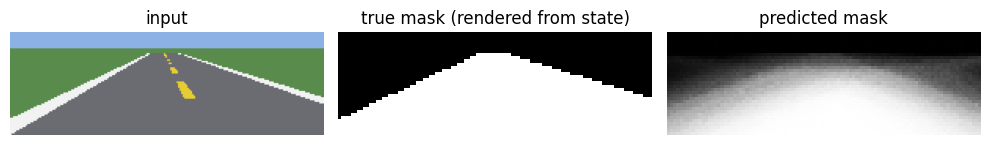

In [16]:
MASK_STYLE = dict(road=(1, 1, 1), lane=(1, 1, 1), dash=(1, 1, 1), sky=(0, 0, 0), grass=(0, 0, 0), brightness=1.0)
def road_mask_from_state(st):                                     # (d, psi, kappa) → (33,100) 0/1
    return (tt.render(float(st[0]), float(st[1]), float(st[2]), style=MASK_STYLE)[::2, ::2, 0] > 127).astype(np.float32)

class SegAuxNet(nn.Module):
    def __init__(self, base):
        super().__init__(); self.features = copy.deepcopy(base.features)
        self.trunk = nn.Sequential(nn.Flatten(), nn.Linear(64 * 18, 100), nn.ReLU()); self.steer_head = nn.Linear(100, 1)
        self.mask_head = nn.Sequential(nn.Linear(64 * 18, 33 * 100), nn.Sigmoid())
    def forward(self, x, with_mask=False):
        f = self.features(x); s = self.steer_head(self.trunk(f))
        return (s, self.mask_head(f.flatten(1)).view(-1, 1, 33, 100)) if with_mask else s

def train_segaux(ds, epochs=3, lam=0.5, n=N_TRAIN, seed=0):
    torch.manual_seed(seed); rng = np.random.RandomState(seed); net = SegAuxNet(v2); opt = torch.optim.Adam(net.parameters(), 3e-4)
    idx_all = rng.choice(len(ds["steers"]), min(n, len(ds["steers"])), replace=False)
    masks = np.stack([road_mask_from_state(ds["states"][k]) for k in idx_all]); mask_of = dict(zip(idx_all.tolist(), range(len(idx_all))))
    ys = torch.from_numpy(ds["steers"]).unsqueeze(1); augf = tt.make_augment(shift=False, seed=seed)     # 시프트는 마스크와 어긋나므로 제외
    for ep in range(epochs):
        net.train(); rng.shuffle(idx_all)
        for j, _ in batches(ds, idx_all):
            imgs, labs = zip(*[augf(ds["images"][k], float(ds["steers"][k])) for k in j])
            x = torch.from_numpy(np.concatenate([tt.preprocess(im) for im in imgs])); y = torch.tensor(labs, dtype=torch.float32).unsqueeze(1)
            m = torch.from_numpy(masks[[mask_of[k] for k in j]]).unsqueeze(1)
            s, mk = net(x, with_mask=True); loss = F.mse_loss(s, y) + lam * F.binary_cross_entropy(mk, m)
            opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

t0 = time.time(); seg = train_segaux(tr)
class SegPolicy:                                                  # 배포: 조향 헤드만
    def __init__(self, net): self.net = net
    def __call__(self, obs, state=None):
        with torch.no_grad(): return float(self.net(torch.from_numpy(tt.preprocess(obs))).item())
pol_seg = SegPolicy(seg); seg_row = dict(model="PilotNet + 세그 보조", **score3(pol_seg))
# 마스크 IoU (검증 200장, 스타일 변경 프레임에서도)
inter = union = 0
for k in range(min(200, len(va["steers"]))):
    with torch.no_grad(): pm = seg(torch.from_numpy(tt.preprocess(va["images"][k])), with_mask=True)[1][0, 0].numpy() > 0.5
    gm = road_mask_from_state(va["states"][k]) > 0.5; inter += (pm & gm).sum(); union += (pm | gm).sum()
seg_row["mask_iou"] = round(inter / max(union, 1), 3); print(seg_row, f"({time.time()-t0:.0f}s)")
k = 0; fig, ax = plt.subplots(1, 3, figsize=(10, 2.2))
with torch.no_grad(): pm = seg(torch.from_numpy(tt.preprocess(va["images"][k])), with_mask=True)[1][0, 0].numpy()
ax[0].imshow(va["images"][k]); ax[0].set_title("input"); ax[1].imshow(road_mask_from_state(va["states"][k]), cmap="gray"); ax[1].set_title("true mask (rendered from state)"); ax[2].imshow(pm, cmap="gray"); ax[2].set_title("predicted mask")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(SAVE_DIR / "seg_aux.png", dpi=110); plt.show()

## 5. 모델 선택 표 — 지연 열이 없으면 표가 아니다
후보 전부를 ONNX 로 내보내 **CPU 지연(배치 1, 200회)·크기·파라미터·L1·L3** 를 한 표에. 파레토 그림(L3 vs 지연)에서 예산 안의 최고를 고르고 `my_policy_v3.onnx` 로 저장합니다.

           model  params  latency_ms  onnx_kb   L1   L3   L2
     PilotNet v2  252219        1.16      988 86.7 25.4 17.3
  PilotNet + 랜덤화  252219        1.10      988 73.0 25.2  9.4
PilotNet + 세그 보조  246749        1.03      966 86.5 33.3 10.5
  MobileNetV3 동결  984809        1.90     3856 57.9  4.5  7.7
MobileNetV3 미세조정  984809        1.91     3856 87.0 10.1  8.9


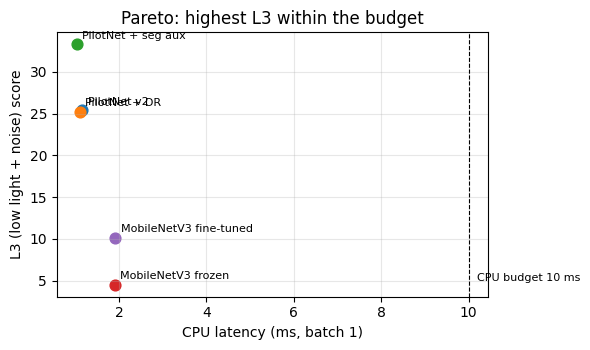

선택: PilotNet + 세그 보조 (L3 33.3, L2 10.5, 1.03 ms) → my_policy_v3.onnx


In [17]:
class SteerOnly(nn.Module):                                      # 세그 보조 넷의 조향 경로만 ONNX 로
    def __init__(self, net): super().__init__(); self.net = net
    def forward(self, x): return self.net(x)
cands = [("PilotNet v2", v2, pol_v2, base_row), ("PilotNet + 랜덤화", pilot_dr, pol_dr, dr_row), ("PilotNet + 세그 보조", SteerOnly(seg), pol_seg, seg_row)]
if HAVE_TV:
    cands += [(rows_bb[0]["model"], mb_frozen, pol_mbf, rows_bb[0]), ("MobileNetV3 미세조정", mb_ft, pol_mbt, rows_bb[1])]
rows = []; sample = D["images"][:200]
for name, model, pol, sc in cands:
    p = tt.export_onnx(model.cpu().eval(), SAVE_DIR / (name.replace(" ", "_").replace("+", "").replace("/", "") + ".onnx"))
    op = tt.OnnxPolicy(p); op(sample[0]); t0 = time.time(); [op(im) for im in sample]; ms = (time.time() - t0) / len(sample) * 1000
    n_params = sum(q.numel() for q in model.parameters()) if not isinstance(model, SteerOnly) else sum(q.numel() for n_, q in model.net.named_parameters() if not n_.startswith("mask_head"))
    rows.append(dict(model=name, params=n_params, latency_ms=round(ms, 2), onnx_kb=os.path.getsize(p) // 1024, L1=sc["L1"], L3=sc["L3"], L2=sc["L2"], onnx=str(p)))
sel = pd.DataFrame(rows); print(sel.drop(columns="onnx").to_string(index=False)); sel.to_csv(SAVE_DIR / "model_selection.csv", index=False)
en = lambda m: m.replace("랜덤화", "DR").replace("세그 보조", "seg aux").replace("동결", "frozen").replace("미세조정", "fine-tuned")   # 그림 라벨은 영문
plt.figure(figsize=(6, 3.6))
for _, r in sel.iterrows():
    plt.scatter(r["latency_ms"], r["L3"], s=60); plt.annotate(en(r["model"]), (r["latency_ms"], r["L3"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.axvline(10, ls="--", c="k", lw=.8); plt.text(10.2, 5, "CPU budget 10 ms", fontsize=8); plt.xlabel("CPU latency (ms, batch 1)"); plt.ylabel("L3 (low light + noise) score"); plt.title("Pareto: highest L3 within the budget"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(SAVE_DIR / "pareto.png", dpi=120); plt.show()
ok = sel[sel["latency_ms"] < 10]; best = ok.sort_values(["L3", "L2"], ascending=False).iloc[0]
import shutil; shutil.copy(best["onnx"], SAVE_DIR / "my_policy_v3.onnx")
print(f"선택: {best['model']} (L3 {best['L3']}, L2 {best['L2']}, {best['latency_ms']} ms) → my_policy_v3.onnx")

## 정리 · 제출
- 색·그림자에는 PilotNet 이 이미 강건하다(형태를 본다). 무너지는 것은 저조도·센서 노이즈 — **데이터 효과**(밝기·노이즈 랜덤화)와 **표현 효과**(백본·세그)를 분리해서 봐야 무엇이 올렸는지 안다.
- 사전학습 백본은 정규화를 모델 안에 넣고 계약(66×200, 0~1)은 그대로. 세그 보조는 배포 때 조향 헤드만.
- 지연 열이 없는 표는 표가 아니다 — 예산 안에서 고른다.

**백본 실험 리포트**: `model_selection.csv` + `pareto.png` + 해석 5줄 → GitHub `week11/` + Mattermost, **11/18(수) 12:00**.
**저장**: `my_policy_v3.onnx`. 다음 주 챌린지 규정이 확정되면 L1~L4 로 자가 평가 (`tools/eval_closed_loop.py --level L3`).